# 02 · PostgreSQL y persistencia

Entiende el modelo relacional y la forma en que el backend conserva el orden, las fechas y la unicidad de las lecturas.

[Índice del backend](README.md) · [Anterior · Arquitectura Python y FastAPI](01_arquitectura_fastapi.ipynb) · [Siguiente · API y autenticación](03_api_y_autenticacion.ipynb)

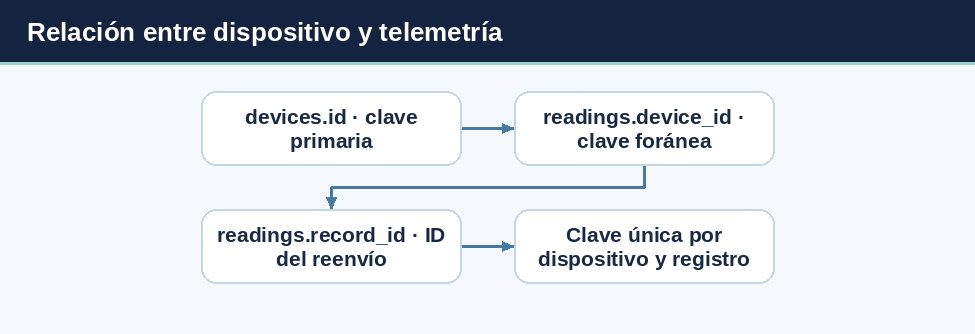

## Tablas y restricciones

| Tabla | Campos principales | Significado |
| --- | --- | --- |
| `users` | `id`, `username`, `password_hash` | Identidades del panel. `id` es una identidad generada y `username` es único. |
| `devices` | `id`, `device_name`, `device_desc` | Dispositivos. El backend registra el ID MQTT. Nombre y descripción son opcionales. |
| `readings` | `id`, `device_id`, `record_id`, `measured_at`, `received_at`, `event_at`, métricas y `calibrated` | Mediciones recibidas y sus fechas. |

Una **clave primaria** identifica una fila. Una **clave foránea** exige que la fila referenciada exista. La relación `devices.id → readings.device_id` es uno a muchos. Las cuentas del panel no se asignan a dispositivos en el esquema actual. Una cuenta válida puede acceder a las rutas de lecturas.

Las métricas son `double precision` y admiten `NULL`. Una muestra sin temperatura válida conserva sus otras mediciones. `calibrated` guarda el indicador booleano recibido en la telemetría de gas.

## Qué significa cada fecha

| Columna | Cómo surge | Uso |
| --- | --- | --- |
| `measured_at` | Hora declarada por el dispositivo si la conocía. Python exige desplazamiento de zona y normaliza a UTC. | Series temporales y orden de las muestras con hora de medición. |
| `received_at` | Hora del servidor PostgreSQL al insertar la fila, con `clock_timestamp()` por defecto. | Auditoría de llegada y respaldo al desconocer la hora medida. |
| `event_at` | Columna generada con `COALESCE(measured_at, received_at)`. | Orden y filtro del historial. |

`timestamptz` representa un instante. Su presentación depende de la zona de la sesión PostgreSQL o del formato que use el cliente. `2026-01-15T08:00:00-06:00` equivale a `2026-01-15T14:00:00Z`. En las dos cadenas cambia la forma de mostrar el instante.

Una fila reenviada puede llegar mucho después de la medición. Priorizar `measured_at` la ubica junto a las mediciones del momento original. Una fila sin reloj sincronizado puede verse en el historial mediante su hora de llegada, conservando un `measured_at` nulo. Las series requieren hora de medición.

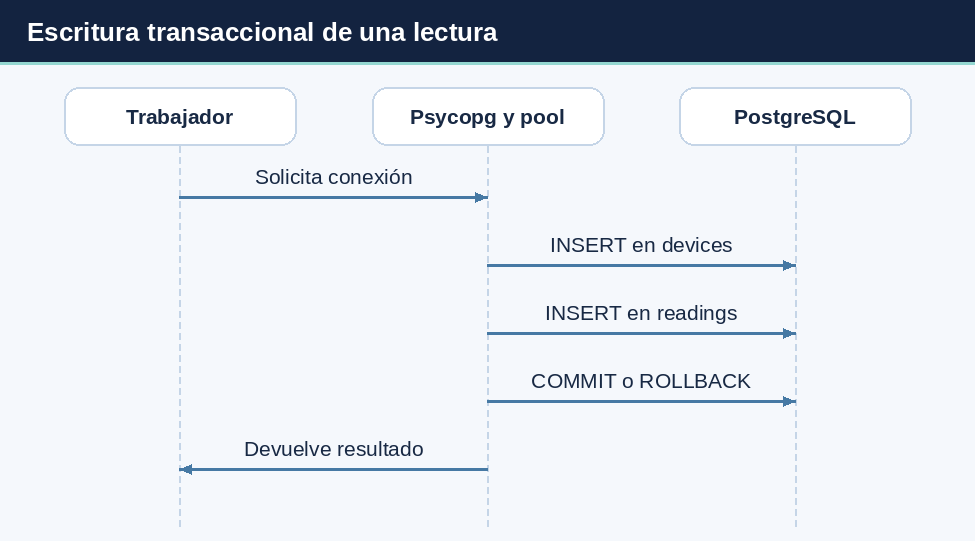

## Pool, transacciones e idempotencia

Un **pool** presta conexiones reutilizables. La configuración usa mínimo 1, máximo 8 y espera de 5 segundos al pedir una conexión. `connect_timeout=5` limita el establecimiento de una nueva conexión. Es un plazo distinto.

`with pool.connection() as conn` devuelve la conexión al pool al terminar. Sin una excepción confirma los cambios y con excepción los revierte. `insert_reading` registra primero el dispositivo con `INSERT ... ON CONFLICT (id) DO NOTHING` y luego intenta guardar la lectura. Ambas escrituras comparten transacción. `dict_row` permite recuperar columnas por nombre, por ejemplo `row["id"]`.

Una operación **idempotente** produce el mismo efecto persistente si se repite la misma entrada. La clave `(device_id, record_id)` identifica un reenvío y la consulta ignora el conflicto. Dos dispositivos pueden usar el mismo `record_id` sin que haya una colisión entre ellos. PostgreSQL admite varios valores `NULL` en esta restricción `UNIQUE`. Por eso las publicaciones normales sin identificador pueden generar múltiples filas para un mismo instante.

## Índices y consultas parametrizadas

El índice de `(device_id, event_at DESC, id DESC)` acompaña el filtro por dispositivo y el orden de la última lectura y el historial. El ID estabiliza el orden si dos filas comparten fecha. El índice parcial de `(device_id, measured_at)` guarda filas con hora de medición, que son las usadas para la serie.

Un índice agiliza búsquedas a cambio de espacio y trabajo de actualización al insertar. El planificador elige cómo acceder a los datos según volumen, selectividad y estadísticas.

El código envía valores separados del SQL mediante marcadores `%s` o `%(device)s`. De esa forma un valor de HTTP o MQTT se interpreta como dato. Las cadenas de SQL concatenadas en el historial son constantes del programa. Conserva esa separación si amplías los filtros.

## Inicialización y actualización del esquema

`db.init_db` toma un bloqueo asesor de PostgreSQL asociado al esquema y ejecuta `backend/schema.sql`. El bloqueo permite serializar inicializaciones concurrentes que siguen el mismo patrón y se libera al confirmar o revertir. El proceso ocurre al arrancar la API y al crear una cuenta en `backend.users`.

El bloque `DO` detecta las tres tablas `dashboard_users`, `dashboard_devices` y `dashboard_readings` si los tres nombres nuevos aún están libres. Las renombra y convierte `dashboard_devices.device_id` en `devices.id`. Además agrega nombre y descripción opcionales a los dispositivos. Renombrar conserva filas, identidades y relaciones existentes. Los índices conservan sus nombres de origen.

En una base vacía se crean las tablas nuevas. Si se mezclan tablas antiguas y nuevas, la condición del renombrado automático no se cumple. Revisa primero los datos de ambos conjuntos si necesitas fusionarlos. Volver a ejecutar `CREATE TABLE IF NOT EXISTS` sirve cuando el esquema ya coincide. Para cambiar en el futuro columnas de tablas ya creadas necesitarás una migración explícita.

## Ejercicio de inspección en pgAdmin

Ejecuta estas consultas de lectura en el **Query Tool** de la base del proyecto. Identifica la base y el rol seleccionados, luego compara los momentos de medición, recepción y evento.

```sql
SELECT current_database(), current_user, current_schema();

SELECT table_schema, table_name
FROM information_schema.tables
WHERE table_name IN ('users', 'devices', 'readings',
                     'dashboard_users', 'dashboard_devices', 'dashboard_readings')
ORDER BY table_schema, table_name;

SELECT device_id, measured_at, received_at, event_at
FROM readings
ORDER BY event_at DESC, id DESC
LIMIT 10;
```

Si encuentras una lectura sin hora de medición, verifica que `event_at` use `received_at`. El resultado puede estar vacío hasta que comience la recepción de telemetría.

[Índice del backend](README.md) · [Anterior · Arquitectura Python y FastAPI](01_arquitectura_fastapi.ipynb) · [Siguiente · API y autenticación](03_api_y_autenticacion.ipynb)